# Multi-step forecasting (6 months ahead)

In this notebook I forecast the next 6 months from the same 36-month window, and compare two ways of doing it. 

The **recursive strategy** reuses the one-step models of notebook 02: it predict one-month, appends the prediction to the end of the window and repeats this 6 times.

The **direct strategy** trains new networks whose last layer gives the 6 months at once. Both are done with the simple RNN and the dense network, and compared with persistence and the linear AR model on the same windows.

The split, the scaling and the training settings come from `src/`, so the errors can be compared with the ones in notebooks 01 and 02.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from src.data import (
    WINDOW,
    load_sunspots,
    make_scaler,
    make_windows,
    rmse_sunspots,
    split_bounds,
    to_sunspots,
)
from src.models import (
    DENSE_HIDDEN,
    RNN_HIDDEN,
    DenseForecaster,
    RecurrentForecaster,
)
from src.style import apply_style
from src.training import (
    MODELS_DIR,
    best_epoch,
    predict,
    predict_recursive,
    train_or_load,
)

# Set this to True for a palette that stays readable with color vision deficiencies.
PALETTE = apply_style(colorblind_safe=False)
# Set this to True to train the direct models again; otherwise their weights are loaded
# from models/03_multi_step/. The one-step models always come from models/02_one_step/.
RETRAIN: bool = False

## 2. Data

Same data as in notebook 01 and 02: the scaler is fitted on train only, and each sample is a 36-month window. The target is now the next 6 months instead of the next one. A window is kept only if its 6 targets months fall inside the same part, so each part loses its last 5 windows compared with notebook 02.
Consecutive windows overlap: in the test phase, most months are forecast by 6 different windows, each at a different number of steps ahead.

In [2]:
HORIZON: int = 6

sunspots = load_sunspots()["Sunspots"]
bounds: dict = split_bounds(len(sunspots))
scaler = make_scaler().fit(sunspots.iloc[slice(*bounds["train"])].to_frame())
scaled = scaler.transform(sunspots.to_frame()).ravel()

windows: dict = {
    name: make_windows(scaled, WINDOW, HORIZON, start, end)
    for name, (start, end) in bounds.items()
}
# The first month forecast by each window; the window also cover the 5 months after it.
target_dates: dict = {
    name: sunspots.index[max(start, WINDOW):end - HORIZON + 1]
    for name, (start, end) in bounds.items()
}

data_summary: dict = {}
for name, (X, y) in windows.items():
    start, end = bounds[name]
    first_target = max(start, WINDOW)
    # The first window ends just before its first target, and its 6 targets are the next 6 months.
    assert X[0, -1, 0] == scaled[first_target - 1]
    assert np.array_equal(y[0], scaled[first_target:first_target + HORIZON])
    # The last window ends at the last month of its part, so no target crosses into the next part.
    assert y[-1, -1] == scaled[end - 1] and len(y) == len(target_dates[name])
    data_summary[name] = {
        "X shape": X.shape, 
        "y shape": y.shape,
        "first target": target_dates[name][0].strftime("%Y-%m"),
        "last target": sunspots.index[end - 1].strftime("%Y-%m"),
    }
pd.DataFrame.from_dict(data_summary, orient="index")

,X shape,y shape,first target,last target
train,"(1763, 36, 1)","(1763, 6)",1752-01,1899-04
validation,"(447, 36, 1)","(447, 6)",1899-05,1936-12
test,"(559, 36, 1)","(559, 6)",1937-01,1983-12


## 3. Baselines

The same two baselines as in notebook 02, now for 6 months. Persistence repeats the last month of the window for all 6 months. The linear AR model is a linear regression on the 36 months with 6 outputs, so it fits one set of coefficients for each step ahead. Both give the 6 months at once and need no training loop, so they are the reference for both strategies. 

With several steps, `rmse_sunspots` computes the RMSE of each step ahead and averages the 6 values. The same number is therefore the mean of the per-step errors shown in section 6.2.

In [3]:
X_train, y_train = windows["train"]
# The linear model needs flat inputs, so the feature axis is dropped.
linear_ar = LinearRegression().fit(X_train[..., 0], y_train)

predictions: dict = {
    "persistence": {name: np.repeat(X[:, -1, :], HORIZON, axis=1) for name, (X, _) in windows.items()},
    "linear AR": {name: linear_ar.predict(X[..., 0]) for name, (X, _) in windows.items()},
}

y_val = windows["validation"][1]
pd.Series(
    {model: rmse_sunspots(scaler, y_val, preds["validation"]) for model, preds in predictions.items()},
    name="validation RMSE",
).round(2)

persistence    19.43
linear AR      16.25
Name: validation RMSE, dtype: float64

## 4. Recursive strategy

The recursive strategy needs no new training. It takes the one-step models of notebook 02, with their 10 seeds and the sizes chosen there, and applies each one 6 times: after every step the forecast is appended as the newest month of the window and the oldest month is dropped. 
From the second step on, the model works on windows that contain its own forecasts, so an error in one month is carried into the next ones.

In [4]:
SEEDS = range(10)

# The first element is the short name used in the file names of models/.
builders: dict = {
    "simple RNN": ("rnn", lambda hidden, horizon: RecurrentForecaster(hidden, horizon)),
    "dense": ("dense", lambda hidden, horizon: DenseForecaster(WINDOW, hidden, horizon)),
}
one_step_hidden: dict = {"simple RNN": RNN_HIDDEN, "dense": DENSE_HIDDEN}

# Only needed if a file of notebook 02 is missing and train_or_load has to train it again.
one_step_windows: dict = {
    name: make_windows(scaled, WINDOW, 1, start, end)
    for name, (start, end) in bounds.items()
}

In [5]:
# Predictions of the 10 seeds of each network, with shape (seeds, windows, 6) for every part.
recursive_predictions: dict = {}
for name, (short_name, build) in builders.items():
    hidden = one_step_hidden[name]
    seed_predictions: dict = {part: [] for part in windows}
    for seed in SEEDS:
        path = MODELS_DIR / "02_one_step" / f"{short_name}_h{hidden}_seed{seed}.pt"
        model, _ = train_or_load(
            lambda: build(hidden, 1), seed, path, one_step_windows["train"], one_step_windows["validation"]
        )
        for part, (X, _) in windows.items():
            seed_predictions[part].append(predict_recursive(model, X, HORIZON))
    recursive_predictions[name] = {part: np.stack(preds) for part, preds in seed_predictions.items()}
    
# Check of the feedback on the last model loaded: step 2 must equal a one-step forecast
# on the window shifted by one month, with the step-1 forecast as its newest month.
X_val = windows["validation"][0]
recursive = predict_recursive(model, X_val, HORIZON)
shifted = np.concatenate([X_val[:, 1:, :], recursive[:, :1, None]], axis=1)
assert np.allclose(recursive[:, 1], predict(model, shifted)[:, 0])

In [6]:
recursive_errors = pd.DataFrame(
    {name: [rmse_sunspots(scaler, y_val, seed_prediction) for seed_prediction in preds["validation"]]
     for name, preds in recursive_predictions.items()},
    index=pd.Index(SEEDS, name="seed"),
)
recursive_errors.agg(["mean", "std"]).T.round(2)

,mean,std
simple RNN,16.12,0.11
dense,15.93,0.15


**Findings:**

Used recursively, both one-step networks are slightly better than the linear AR model on validation ($16.25$ in section 3): $16.12$ for the simple RNN and $15.93$ for the dense network. Their spread over seeds ($0.11$ and $0.15$) is about twice the one they had one step ahead ($0.05$ and $0.08$ in notebook 02, section 5.1), which fits with errors being carried from one step to the next. 
These are validation numbers only; the comparison with the direct strategy and on the test period is in section 6.

## 5. Direct strategy

The direct strategy trains new networks whose last layer has 6 units, one for each month ahead, and the loss is the MSE over the 6 months. The networks and the training settings are the same as in notebook 02; only the output changes. 
A network with 6 outputs solves a harder task than one with a single output, so I search the hidden size again with the same procedure as in notebook 02, section 5.1: $16$, $32$ and $64$ units, 10 seeds each, and the size with the lowest mean validation RMSE. The weights are saved in `models/03_multi_step/`.

In [7]:
CANDIDATE_HIDDEN: list[int] = [16, 32, 64]

X_val, y_val = windows["validation"]
runs: dict = {}
search: dict = {}
for name, (short_name, build) in builders.items():
    for hidden in CANDIDATE_HIDDEN:
        for seed in SEEDS:
            path = MODELS_DIR / "03_multi_step" / f"{short_name}_h{hidden}_seed{seed}.pt"
            model, history = train_or_load(
                lambda: build(hidden, HORIZON), seed, path, windows["train"], windows["validation"], RETRAIN
            )
            runs[(name, hidden, seed)] = model
            search[(name, hidden, seed)] = {
                "validation RMSE": rmse_sunspots(scaler, y_val, predict(model, X_val)),
                "best epoch": best_epoch(history),
            }

search_results = pd.DataFrame.from_dict(search, orient="index").rename_axis(["model", "hidden", "seed"])
search_results.groupby(level=["model", "hidden"], sort=False).agg(["mean", "std", "sem"]).round(2)

validation RMSE             best epoch              
                             mean   std   sem       mean    std    sem
model      hidden                                                     
simple RNN 16               16.18  0.07  0.02       65.5  19.02   6.02
           32               16.06  0.08  0.03       39.2  18.08   5.72
           64               16.07  0.13  0.04       24.0  12.28   3.88
dense      16               16.11  0.28  0.09       62.2  31.14   9.85
           32               15.98  0.25  0.08       56.6  32.34  10.23
           64               15.87  0.10  0.03       42.7  13.98   4.42

**Findings:**

The search ends with the same sizes as one step ahead. For the simple RNN, 32 and 64 units are practically tied ($16.06$ and $16.07$, with sems of $0.03$ and $0.04$), so I keep the smaller one. For the dense network, 64 units give $15.87$ against $15.98$ with 32, a gap only slightly larger than the sem of 32 units ($0.08$), but 64 units are also much more stable over seeds (standard deviation $0.10$ against $0.25$), so I keep 64. Both sizes are therefore the ones of notebook 02 (`RNN_HIDDEN` and `DENSE_HIDDEN` in `src/models.py`), so the recursive and the direct model of each network differ only in their output.

In [8]:
# The search picks the same sizes as notebook 02.
direct_hidden: dict = {"simple RNN": RNN_HIDDEN, "dense": DENSE_HIDDEN}

# Predictions of the 10 seeds of each network, with shape (seeds, windows, 6) for every part
direct_predictions: dict = {
    name: {
        part: np.stack([predict(runs[(name, direct_hidden[name], seed)], X) for seed in SEEDS])
        for part, (X, _) in windows.items()
    }
    for name in builders
}
assert all(
    direct_predictions[name][part].shape == recursive_predictions[name][part].shape
    # Every network and every part
    for name in builders for part in windows # (Yes... doubled nested loop in list comprehension.)
)

## 6. Test evaluation

The test period is used only here, once the sizes are fixed.
Each network is evaluated with its 10 seeds and both strategies, and the baselines with the same windows. As in notebook 02, every error is also divided by the error of persistence on the same period, so validation and test can be compared even though the test period is more active.

### 6.1 Errors

In [9]:
# One entry per network and strategy, with shape (seeds, windows, 6) for every part.
network_predictions: dict = {
    f"{name} {strategy}": strategy_predictions[name]
    for name in builders
    for strategy, strategy_predictions in (("recursive", recursive_predictions), ("direct", direct_predictions))
}

records: list[dict] = []
for part in ("validation", "test"):
    y = windows[part][1]
    for name, preds in predictions.items():
        records.append({"model": name, "part": part, "RMSE": rmse_sunspots(scaler, y, preds[part])})
    for name, preds in network_predictions.items():
        for seed_prediction in preds[part]:
            records.append({"model": name, "part": part, "RMSE": rmse_sunspots(scaler, y, seed_prediction)})

errors = pd.DataFrame(records).groupby(["model", "part"], sort=False)["RMSE"]
results = pd.DataFrame({
    "validation RMSE": errors.mean().xs("validation", level="part"),
    "test RMSE": errors.mean().xs("test", level="part"),
    # The baselines are deterministic, so their spread over seeds is NaN.
    "test std over seeds": errors.std().xs("test", level="part"),
    "test sem": errors.sem().xs("test", level="part"),
})
for part in ("validation", "test"):
    results[f"{part} / persistence"] = results[f"{part} RMSE"] / results.loc["persistence", f"{part} RMSE"]
results.round(2)

,validation RMSE,test RMSE,test std over seeds,test sem,validation / persistence,test / persistence
model,,,,,,
persistence,19.43,26.45,NaN,NaN,1.00,1.00
linear AR,16.25,22.25,NaN,NaN,0.84,0.84
simple RNN recursive,16.12,23.61,1.19,0.38,0.83,0.89
simple RNN direct,16.06,22.84,0.45,0.14,0.83,0.86
dense recursive,15.93,22.42,1.07,0.34,0.82,0.85
dense direct,15.87,21.39,0.34,0.11,0.82,0.81


**Findings:**

On validation the two strategies are practically tied for each network ($16.06$ against $16.12$ for the simple RNN, $15.87$ against $15.93$ for the dense network). On test the direct strategy is better for both, by more than its sems: $22.84$ against $23.61$ for the simple RNN, and $21.39$ against $22.42$ for the dense network. The direct dense network is the only model below the linear AR model on test ($21.39$ against $22.25$).

The recursive models are also less consistent on test, with a standard deviation over seeds of $1.19$ and $1.07$, against $0.45$ and $0.34$ for the direct ones.

### 6.2 Error at each step ahead

The averages above hide how the error grows with the horizon. Here I compute the test RMSE of each step ahead separately; for the networks it is the mean over the 10 seeds. Averaging the 6 values of a row gives back its test RMSE of section 6.1.

In [10]:
y_test = to_sunspots(scaler, windows["test"][1])


def step_rmse(prediction: np.ndarray) -> np.ndarray:
    # RMSE in sunspots of each step ahead, one value per column.
    return np.sqrt(np.mean((y_test - to_sunspots(scaler, prediction)) ** 2, axis=0))


step_errors = pd.DataFrame(
    {name: step_rmse(preds["test"]) for name, preds in predictions.items()}
    | {name: np.mean([step_rmse(seed_prediction) for seed_prediction in preds["test"]], axis=0)
       for name, preds in network_predictions.items()},
    index=pd.Index(range(1, HORIZON + 1), name="step ahead"),
)
# The mean over the 6 steps must give back the test RMSE of section 6.1.
assert np.allclose(step_errors.mean(), results.loc[step_errors.columns, "test RMSE"])
step_errors.T.round(2)

step ahead,1,2,3,4,5,6
persistence,20.13,24.49,26.02,27.52,29.31,31.23
linear AR,18.35,20.94,22.05,23.08,24.06,24.98
simple RNN recursive,18.89,21.91,23.36,24.63,25.85,27.05
simple RNN direct,19.56,21.84,22.80,23.65,24.22,24.99
dense recursive,18.69,21.11,22.19,23.20,24.21,25.10
dense direct,18.67,20.64,21.24,21.92,22.73,23.14


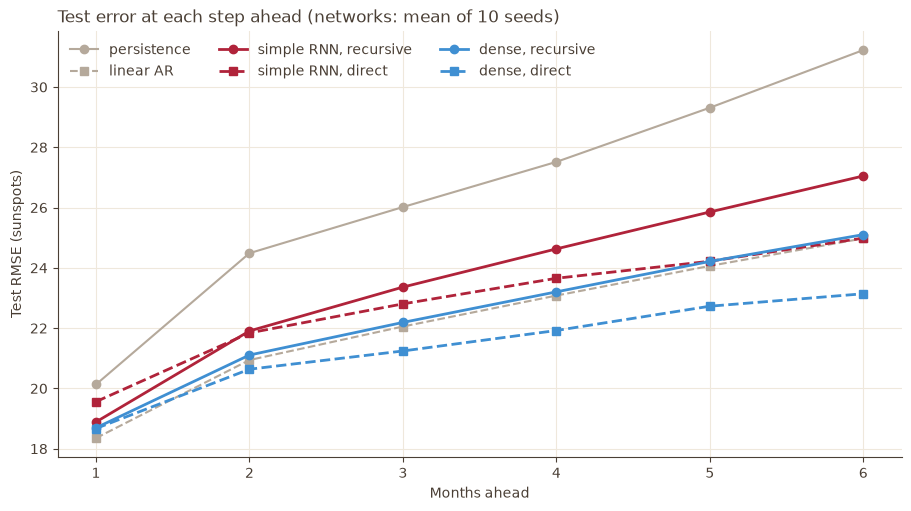

In [11]:
steps = step_errors.index
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

ax.plot(steps, step_errors["persistence"], color=PALETTE.muted, linewidth=1.5, marker="o", label="persistence")
ax.plot(steps, step_errors["linear AR"], color=PALETTE.muted, linewidth=1.5, linestyle="--", marker="s",
        label="linear AR")
# Color follows the network and the line style follows the strategy.
for name in builders:
    for strategy, linestyle, marker in (("recursive", "-", "o"), ("direct", "--", "s")):
        ax.plot(steps, step_errors[f"{name} {strategy}"], color=PALETTE.color(name), linewidth=2,
                linestyle=linestyle, marker=marker, label=f"{name}, {strategy}")

ax.set_xticks(steps)
ax.set_xlabel("Months ahead")
ax.set_ylabel("Test RMSE (sunspots)")
ax.set_title("Test error at each step ahead (networks: mean of 10 seeds)", loc="left")
ax.legend(frameon=False, ncols=3, loc="upper left")

plt.show()

**Findings:**

One month ahead all the models are close, between $18.35$ and $19.56$. From the second or third step on, the direct curve of each network is below its recursive one, and the gap grows with the horizon: at 6 months it is $24.99$ against $27.05$ for the simple RNN, and $23.14$ against $25.10$ for the dense network. The recursive curves grow faster because each step feeds its error into the next one: the errors are cumulative.

So the direct strategy works better here, and its advantage comes from the later steps. The direct dense network grows the least, from $18.67$ to $23.14$, and ends below the linear AR model at 6 months ($24.98$).

### 6.3 Actual and predicted values

With 6 steps there are several forecasts for each month, so I show them in two ways.
The top panel draws, for every month, the forecast made 6 months before it, which is the hardest step, with the direct simple RNN. The zoom draws whole 6-month forecasts from one origin every 6 months, so they do not overlap, for both strategies of the simple RNN. Each segment starts from a window of actual values and shows how the forecast moves away from them.

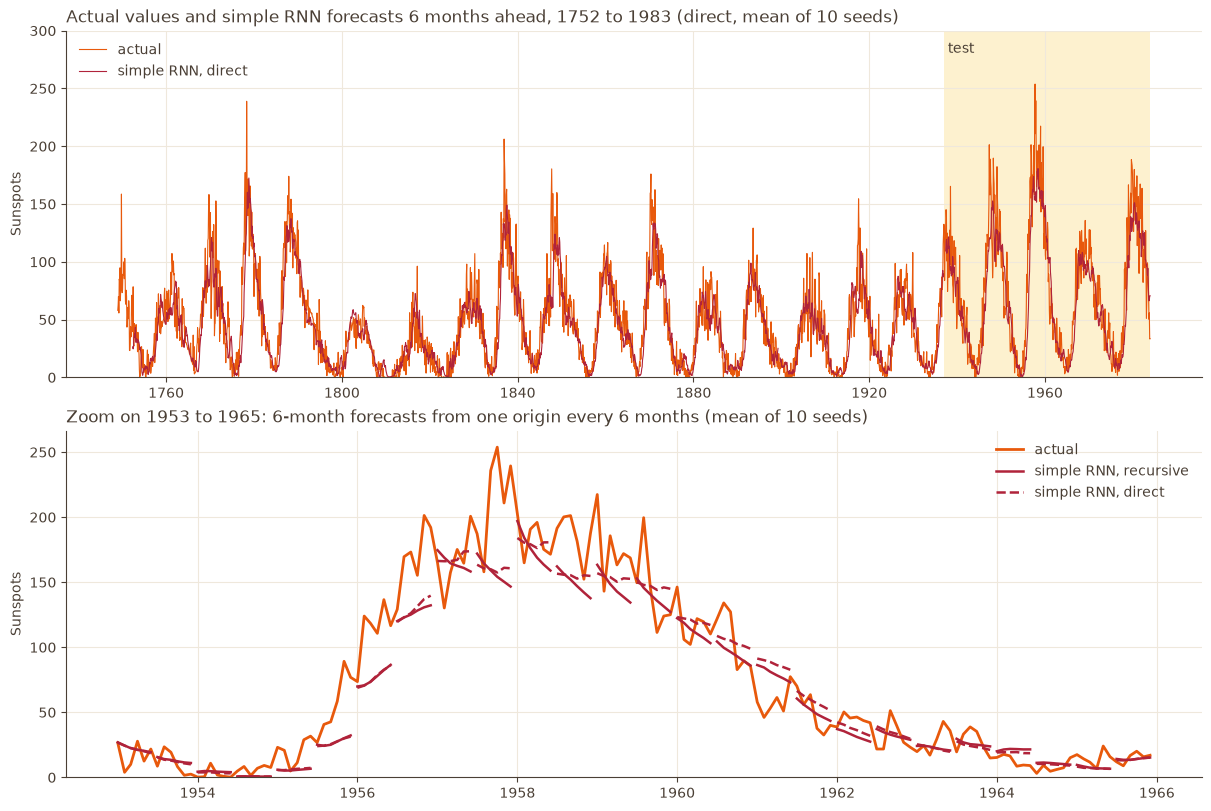

In [12]:
ZOOM: tuple[str, str] = ("1953-01", "1965-12")
test_start = target_dates["test"][0]


def in_sunspots(name: str, part: str) -> np.ndarray:
    # (seeds, windows, 6) in sunspots, from the scaled predictions of every seed.
    return to_sunspots(scaler, network_predictions[name][part])


fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")

ax_full.axvspan(test_start, sunspots.index[-1], color=PALETTE.highlight, linewidth=0)
ax_full.plot(sunspots.index, sunspots, color=PALETTE.color("actual"), linewidth=0.8, label="actual")
for part in ("train", "validation", "test"):
    # The 6th step of a window lands 5 months after its first target.
    sixth_month = target_dates[part] + pd.DateOffset(months=HORIZON - 1)
    ax_full.plot(sixth_month, in_sunspots("simple RNN direct", part)[..., -1].mean(axis=0),
                 color=PALETTE.color("simple RNN"), linewidth=0.8,
                 label="simple RNN, direct" if part == "train" else None)
ax_full.text(test_start, 290, " test", va="top", color=PALETTE.ink)
ax_full.set_ylim(0, 300)
ax_full.set_title("Actual values and simple RNN forecasts 6 months ahead, 1752 to 1983 (direct, mean of 10 seeds)",
                  loc="left")
ax_full.set_ylabel("Sunspots")
ax_full.legend(loc="upper left", frameon=False)

dates = target_dates["test"]
origins = np.flatnonzero((dates >= ZOOM[0]) & (dates <= ZOOM[1]))[::HORIZON]
in_zoom = (sunspots.index >= ZOOM[0]) & (sunspots.index <= ZOOM[1])
ax_zoom.plot(sunspots.index[in_zoom], sunspots[in_zoom], color=PALETTE.color("actual"), linewidth=2, label="actual")
for strategy, linestyle in (("recursive", "-"), ("direct", "--")):
    forecasts = in_sunspots(f"simple RNN {strategy}", "test").mean(axis=0)
    for k, i in enumerate(origins):
        months = pd.date_range(dates[i], periods=HORIZON, freq="MS")
        ax_zoom.plot(months, forecasts[i], color=PALETTE.color("simple RNN"), linewidth=1.8, linestyle=linestyle,
                     label=f"simple RNN, {strategy}" if k == 0 else None)
ax_zoom.set_title("Zoom on 1953 to 1965: 6-month forecasts from one origin every 6 months (mean of 10 seeds)",
                  loc="left")
ax_zoom.set_ylabel("Sunspots")
ax_zoom.set_ylim(bottom=0)
ax_zoom.legend(loc="upper right", frameon=False)

plt.show()

**Findings:**

Six months ahead the direct simple RNN still follows the cycle over the whole series, in the test period as well, but its forecasts are smoother than the actual values and stay below them at the peaks.

The zoom shows how the two strategies differ inside one forecast. Every segment starts close to the actual values, since its first month comes from a window of known months. Around the maximum of 1957 to 1959 the recursive segments bend down faster than the direct ones, so after a few months they are further from the actual values: each recursive step works on the lower forecasts of the step before. At low activity, after 1962, the two strategies almost overlap. This is the same pattern as in section 6.2, where the gap between the strategies grows with the horizon.

## 7. Summary

What the next notebook reuses:

- **Sizes:** the search for the direct models picks the same sizes as one step ahead, 32 hidden units for the simple RNN and 64 for the dense network (section 5), so `RNN_HIDDEN` and `DENSE_HIDDEN` hold for both strategies.

- **Recursive forecasts:** `predict_recursive` in `src/training.py` turns any one-step model into a 6-month forecast, so the LSTM and the GRU can be compared with both strategies without new code.

What the 6-month comparison shows:

- **Which strategy works better:** the direct one. On validation the two are practically tied, but on test the direct strategy has the lower error for both networks: $22.84$ against $23.61$ for the simple RNN, and $21.39$ against $22.42$ for the dense network (section 6.1). The direct models are also more consistent over seeds.

- **Where the difference comes from:** one month ahead the strategies are close, and the gap grows with the horizon. At 6 months it is $24.99$ against $27.05$ for the simple RNN, and $23.14$ against $25.10$ for the dense network (section 6.2). Near the maximum of 1957 the recursive forecasts fall below the direct ones, since each step starts from the low forecats of the steps before (section 6.3). This is the build-up of the high-level bias that notebook 02 anticipated.

- **Against the baselines:** every network beats persistence ($26.45$), but only the direct dense network beats the linear AR model ($21.39$ against $22.25$). The simple RNN stays above it with both strategies. 